In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/telco_churn.csv")
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
print("\nMissing value per kolom:")
print(df.isnull().sum())
print("\nProporsi Churn:")
print(df["Churn"].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing value TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing value TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


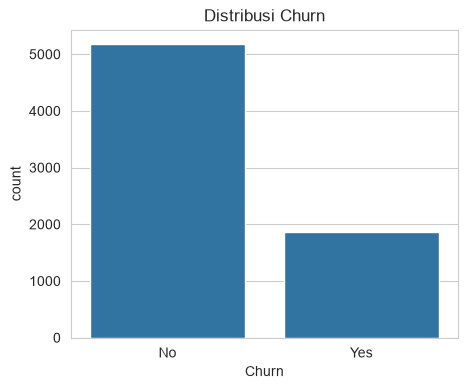

C:\Users\Leonvo\AppData\Local\Temp\ipykernel_7356\2433094659.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("../images/churn_contract.png", dpi=150, bbox_inches="tight")


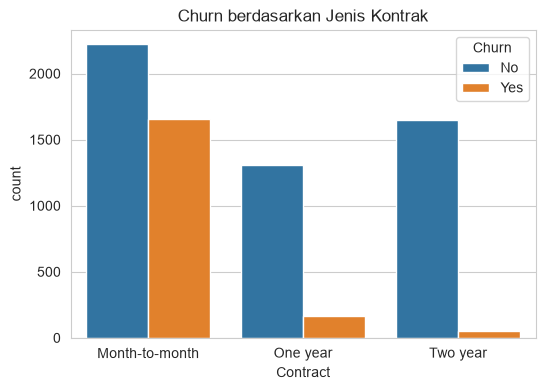

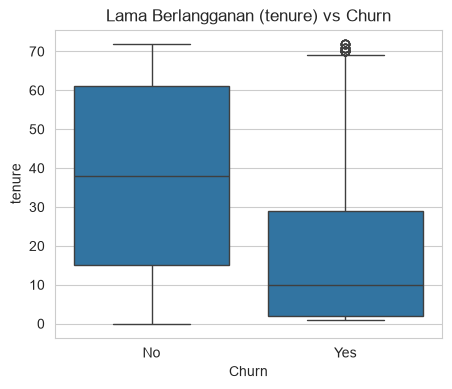

In [4]:
import os
os.makedirs("../images", exist_ok=True)

sns.set_style("whitegrid")

# 1. Distribusi churn
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn")
plt.title("Distribusi Churn")
plt.savefig("../images/churn_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Churn berdasarkan jenis kontrak
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn berdasarkan Jenis Kontrak")
plt.savefig("../images/churn_contract.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Tenure vs churn
plt.figure(figsize=(5, 4))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Lama Berlangganan (tenure) vs Churn")
plt.savefig("../images/churn_tenure.png", dpi=150, bbox_inches="tight")
plt.show()